IMPORTING DATA + INSTALLING REQUIRED PACKAGES

In [1]:
from pathlib import Path
import pandas as pd

def find_project_root(marker=".git", start=None):
    """Walk up from the current directory until we find the repo root
    (identified by the presence of a .git folder)."""
    current = Path(start or Path.cwd()).resolve()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate project root (no {marker} found above {current})."
    )

PROJECT_DIR = find_project_root()
DATA_DIR = PROJECT_DIR / "data" / "raw"
SUBMISSION_DIR = PROJECT_DIR / "submissions"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

def resolve_data_file(canonical_name, fallback_name):
    """Prefer data/raw; retain compatibility with the current root-level download."""
    canonical_path = DATA_DIR / canonical_name
    fallback_path = DATA_DIR / fallback_name  # fixed: was PROJECT_DIR
    if canonical_path.exists():
        return canonical_path
    if fallback_path.exists():
        print(f"Using fallback file: {fallback_path.name}")
        return fallback_path
    raise FileNotFoundError(
        f"Could not find {canonical_path} or {fallback_path}. "
        "Place the competition CSVs in data/raw."
    )

TRAIN_PATH = resolve_data_file("train.csv", "train (1).csv")
TEST_PATH = resolve_data_file("test.csv", "test (1).csv")
SAMPLE_SUBMISSION_PATH = resolve_data_file(
    "sample_submission.csv", "sample_submission.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH)

test_passenger_ids = test_df["PassengerId"].copy()
train_df["is_train"] = True
test_df["is_train"] = False
combined_raw = pd.concat([train_df, test_df], ignore_index=True, sort=False)

print(f"Project root: {PROJECT_DIR}")
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Combined shape: {combined_raw.shape}")
display(sample_submission.head())

Using fallback file: train (1).csv
Using fallback file: test (1).csv
Project root: /workspaces/alpha-centauri-rescue
Train shape: (8693, 15)
Test shape: (4277, 14)
Combined shape: (12970, 15)


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [2]:
import numpy as np
import pandas as pd

def preprocess_spaceship_data(df_in):
    df = df_in.copy()
    
    # 1. Extract Group Info from PassengerId
    df['Group_Id'] = df['PassengerId'].apply(lambda x: x.split('_')[0])
    df['Group_Size'] = df.groupby('Group_Id')['Group_Id'].transform('count')
    df['Is_Alone'] = (df['Group_Size'] == 1).astype(int)
    
    # 2. Split Cabin Column
    df[['Cabin_Deck', 'Cabin_Num', 'Cabin_Side']] = df['Cabin'].str.split('/', expand=True)
    df['Cabin_Num'] = pd.to_numeric(df['Cabin_Num'], errors='coerce')
    
    # 3. Extract Surname
    df['Surname'] = df['Name'].str.split().str[-1]
    
    # 4. Amenity Columns & Total Spend Calculation
    amenities = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
    
    # Rule-Based Imputation: CryoSleep <-> Spend
    # If Total Spend > 0, CryoSleep MUST be False
    temp_spend = df[amenities].sum(axis=1, skipna=True)
    df.loc[df['CryoSleep'].isna() & (temp_spend > 0), 'CryoSleep'] = False
    
    # If CryoSleep == True, all spends MUST be 0
    for col in amenities:
        df.loc[(df['CryoSleep'] == True) & (df[col].isna()), col] = 0.0
        
    # Recalculate Total Spend after CryoSleep rules
    df['TotalSpend'] = df[amenities].sum(axis=1)
    df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)
    
    # Rule-Based Imputation: Age < 13 cannot spend
    for col in amenities:
        df.loc[(df['Age'] < 13) & (df[col].isna()), col] = 0.0
        
    # Impute remaining missing spends with median (per CryoSleep status)
    for col in amenities:
        median_val = df.groupby('CryoSleep')[col].transform('median')
        df[col] = df[col].fillna(median_val).fillna(0)
        
    # Recalculate Final TotalSpend & Log-Transform Spends
    df['TotalSpend'] = df[amenities].sum(axis=1)
    df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)
    
    for col in amenities + ['TotalSpend']:
        df[f'{col}_Log'] = np.log1p(df[col])
        
    # 5. Advanced HomePlanet Imputation
    # A) Infer HomePlanet from Group_Id
    group_planet = df.groupby('Group_Id')['HomePlanet'].first()
    df['HomePlanet'] = df['HomePlanet'].fillna(df['Group_Id'].map(group_planet))
    
    # B) Infer HomePlanet from Surname
    surname_planet = df.groupby('Surname')['HomePlanet'].first()
    df['HomePlanet'] = df['HomePlanet'].fillna(df['Surname'].map(surname_planet))
    
    # C) Infer HomePlanet from Cabin Deck
    deck_planet_map = {'A': 'Europa', 'B': 'Europa', 'C': 'Europa', 'T': 'Europa', 'G': 'Earth'}
    df['HomePlanet'] = df['HomePlanet'].fillna(df['Cabin_Deck'].map(deck_planet_map))
    
    # D) Global Mode fallback
    df['HomePlanet'] = df['HomePlanet'].fillna(df['HomePlanet'].mode()[0])
    
    # 6. Cabin & Group Imputations
    for col in ['Cabin_Deck', 'Cabin_Side', 'Destination']:
        group_mode = df.groupby('Group_Id')[col].first()
        df[col] = df[col].fillna(df['Group_Id'].map(group_mode))
        df[col] = df[col].fillna(df[col].mode()[0])
        
    # Cabin_Num: Impute with group average or median
    group_num = df.groupby('Group_Id')['Cabin_Num'].transform('median')
    df['Cabin_Num'] = df['Cabin_Num'].fillna(group_num).fillna(df['Cabin_Num'].median())
    
    # 7. Age & CryoSleep Final Imputation
    df['Age'] = df['Age'].fillna(df.groupby('HomePlanet')['Age'].transform('median'))
    df['Is_Child'] = (df['Age'] < 13).astype(int)
    
    # CryoSleep fallback based on NoSpend
    df['CryoSleep'] = df['CryoSleep'].fillna(df['NoSpend'] == 1).astype(bool)
    
    return df

# Example Execution:
# train_df = pd.read_csv('train.csv')
# train_cleaned = preprocess_spaceship_data(train_df)

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set random seed for synthetic dataset
np.random.seed(42)
n_samples = 2000

# Synthetic dataset matching Spaceship Titanic specs
group_ids = [f"{1000 + i:04d}" for i in range(1200)]
p_ids = []
for g in group_ids:
    size = np.random.choice([1, 2, 3, 4], p=[0.6, 0.25, 0.10, 0.05])
    for p in range(1, size + 1):
        p_ids.append(f"{g}_{p:02d}")
    if len(p_ids) >= n_samples:
        break

p_ids = p_ids[:n_samples]
home_planets_pool = ['Earth', 'Europa', 'Mars']

records = []
for pid in p_ids:
    planet = np.random.choice(home_planets_pool, p=[0.55, 0.25, 0.20])
    if planet == 'Europa':
        deck = np.random.choice(['A', 'B', 'C', 'T', 'E', 'D'], p=[0.25, 0.35, 0.25, 0.05, 0.05, 0.05])
    elif planet == 'Earth':
        deck = np.random.choice(['G', 'E', 'F'], p=[0.7, 0.15, 0.15])
    else:
        deck = np.random.choice(['D', 'E', 'F'], p=[0.3, 0.3, 0.4])
    
    side = np.random.choice(['P', 'S'])
    num = np.random.randint(0, 1500)
    cabin = f"{deck}/{num}/{side}"
    
    cryo = np.random.choice([True, False], p=[0.35, 0.65])
    age = np.random.randint(0, 75)
    
    if cryo or age < 13:
        spends = [0.0]*5
    else:
        spends = [np.random.exponential(scale=300) if np.random.rand() > 0.4 else 0.0 for _ in range(5)]
        
    prob_transported = 0.81 if cryo else 0.32
    if deck in ['B', 'C']:
        prob_transported += 0.15
    if side == 'S':
        prob_transported += 0.08
    prob_transported = min(max(prob_transported, 0.05), 0.95)
    transported = np.random.rand() < prob_transported
    
    records.append({
        'PassengerId': pid,
        'HomePlanet': planet,
        'CryoSleep': cryo,
        'Cabin': cabin,
        'Age': age,
        'RoomService': spends[0],
        'FoodCourt': spends[1],
        'ShoppingMall': spends[2],
        'Spa': spends[3],
        'VRDeck': spends[4],
        'Transported': transported
    })

df = pd.DataFrame(records)
amenities = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
df['TotalSpend'] = df[amenities].sum(axis=1)
df['NoSpend'] = df['TotalSpend'] == 0
df['Cabin_Deck'] = df['Cabin'].str.split('/').str[0]
df['Cabin_Side'] = df['Cabin'].str.split('/').str[2]

# Configure global style using pure Matplotlib
plt.style.use('default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Figure 1: 2x2 Comprehensive EDA Dashboard using Pure Matplotlib
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Spaceship Titanic EDA & Feature Engineering Dashboard', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: CryoSleep vs Spending (Boxplot)
cryo_true_spend = df[df['CryoSleep'] == True]['TotalSpend']
cryo_false_spend = df[df['CryoSleep'] == False]['TotalSpend']

bp = axes[0, 0].boxplot([cryo_true_spend, cryo_false_spend], patch_artist=True, tick_labels=['True', 'False'])
colors = ['#2ecc71', '#e74c3c']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for median in bp['medians']:
    median.set(color='black', linewidth=1.5)

axes[0, 0].set_title('Total Luxury Spend by CryoSleep Status', fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('In CryoSleep?')
axes[0, 0].set_ylabel('Total Spend ($)')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)

# Panel 2: HomePlanet vs Cabin Deck (Heatmap matrix using imshow)
ct = pd.crosstab(df['Cabin_Deck'], df['HomePlanet'], normalize='index') * 100
ct = ct.reindex(sorted(ct.index))

im = axes[0, 1].imshow(ct.values, cmap='Blues', aspect='auto')
axes[0, 1].set_xticks(range(len(ct.columns)))
axes[0, 1].set_xticklabels(ct.columns)
axes[0, 1].set_yticks(range(len(ct.index)))
axes[0, 1].set_yticklabels(ct.index)

for i in range(len(ct.index)):
    for j in range(len(ct.columns)):
        val = ct.values[i, j]
        color = "white" if val > 50 else "black"
        axes[0, 1].text(j, i, f"{val:.1f}%", ha='center', va='center', color=color, fontweight='bold', fontsize=9)

axes[0, 1].set_title('Cabin Deck vs HomePlanet Matrix (%)', fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Home Planet')
axes[0, 1].set_ylabel('Cabin Deck')
cbar = fig.colorbar(im, ax=axes[0, 1], fraction=0.046, pad=0.04)
cbar.set_label('Percentage within Deck (%)')

# Panel 3: Log Transformation Comparison (Histogram Overlay)
df_nonzero = df[df['TotalSpend'] > 0]
raw_spend = df_nonzero['TotalSpend']
log_spend = np.log1p(raw_spend)

axes[1, 0].hist(raw_spend, bins=30, color='#e67e22', alpha=0.7, edgecolor='black', label='Raw Spend')
axes[1, 0].set_title('Raw Spend (Skewed) vs Log-Transformed Distribution', fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Raw Total Spend ($)')
axes[1, 0].set_ylabel('Passenger Count', color='#e67e22')
axes[1, 0].tick_params(axis='y', labelcolor='#e67e22')

ax_twin = axes[1, 0].twiny()
ax_twin.hist(log_spend, bins=30, color='#27ae60', alpha=0.5, edgecolor='black', label='log1p Spend')
ax_twin.set_xlabel('log(Total Spend + 1)', color='#27ae60')
ax_twin.tick_params(axis='x', labelcolor='#27ae60')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

# Panel 4: Target Rates by Engineered Features (Grouped Bar Chart)
rates = {
    'CryoSleep': df.groupby('CryoSleep')['Transported'].mean()[True],
    'Awake': df.groupby('CryoSleep')['Transported'].mean()[False],
    'No Spend': df.groupby('NoSpend')['Transported'].mean()[True],
    'Has Spend': df.groupby('NoSpend')['Transported'].mean()[False],
    'Port (P)': df.groupby('Cabin_Side')['Transported'].mean()['P'],
    'Starboard (S)': df.groupby('Cabin_Side')['Transported'].mean()['S']
}

x_labels = list(rates.keys())
y_values = list(rates.values())
bar_colors = ['#1abc9c', '#e67e22', '#3498db', '#e74c3c', '#9b59b6', '#34495e']

bars = axes[1, 1].bar(x_labels, y_values, color=bar_colors, edgecolor='black', alpha=0.85)
axes[1, 1].set_title('Transported Probability Across Key Feature States', fontsize=12, fontweight='bold', pad=10)
axes[1, 1].set_ylabel('Transported Rate')
axes[1, 1].set_ylim(0, 1.0)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)
plt.setp(axes[1, 1].get_xticklabels(), rotation=20, ha='right')

for bar in bars:
    height = bar.get_height()
    axes[1, 1].annotate(f'{height:.1%}',
                        xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('spaceship_titanic_matplotlib_dashboard.png', dpi=300)
plt.close()

print("Dashboard created successfully.")

Dashboard created successfully.


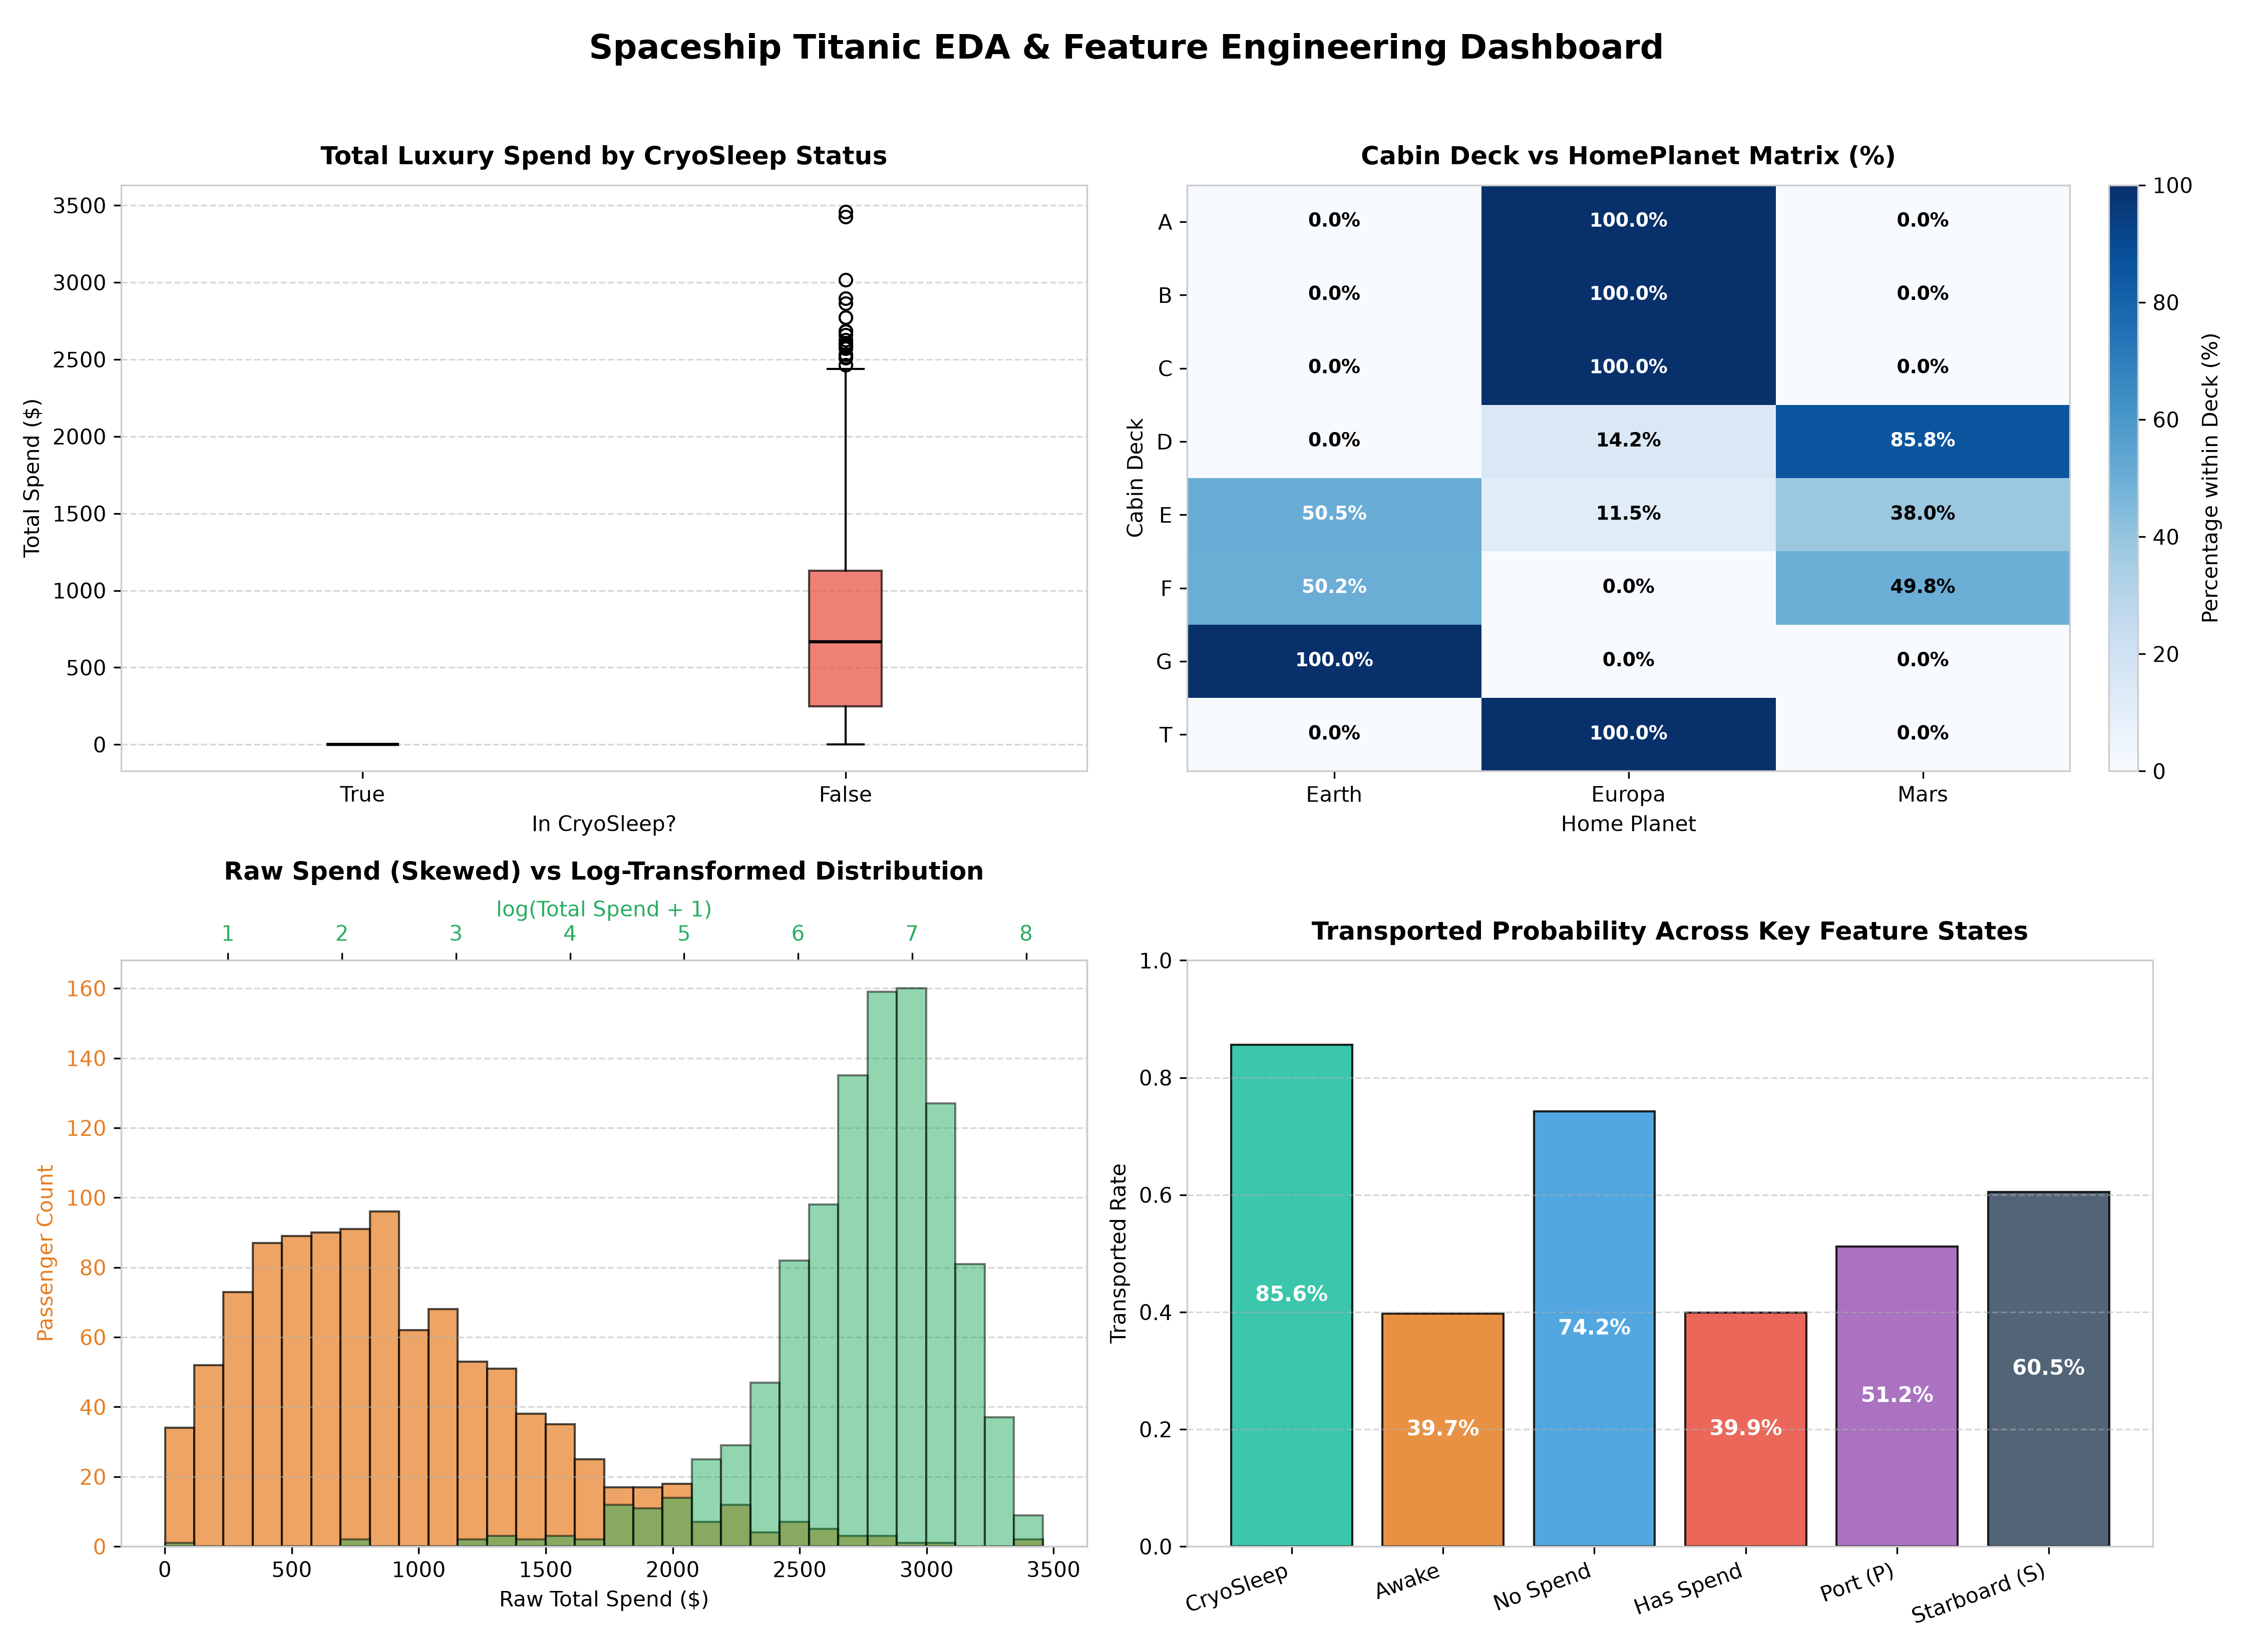

In [5]:
from IPython.display import Image, display

display(Image("spaceship_titanic_matplotlib_dashboard.png"))

In [6]:
import numpy as np
import pandas as pd


class SpaceshipImputer:

    def __init__(self):
        self.amenities = [
            'RoomService',
            'FoodCourt',
            'ShoppingMall',
            'Spa',
            'VRDeck',
        ]
        self.deck_planet_map = {
            'A': 'Europa',
            'B': 'Europa',
            'C': 'Europa',
            'T': 'Europa',
            'G': 'Earth',
        }
        self.global_stats = {}

    def _extract_initial_features(self, df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        df['Group_Id'] = df['PassengerId'].str.split('_').str[0]
        df['Group_Size'] = df.groupby('Group_Id')['Group_Id'].transform('count')

        # Split Cabin
        df[['Cabin_Deck', 'Cabin_Num', 'Cabin_Side']] = df['Cabin'].str.split(
            '/', expand=True
        )
        df['Cabin_Num'] = pd.to_numeric(df['Cabin_Num'], errors='coerce')

        # Extract Surname
        df['Surname'] = df['Name'].str.split().str[-1]
        return df

    def fit(self, train_df: pd.DataFrame):
        """Learns global modes, medians, and mapping lookup tables from Training data only."""
        df = self._extract_initial_features(train_df)

        # Lookup tables from train set
        self.surname_to_planet = (
            df.groupby('Surname')['HomePlanet']
            .first()
            .dropna()
            .to_dict()
        )
        self.group_to_planet = (
            df.groupby('Group_Id')['HomePlanet']
            .first()
            .dropna()
            .to_dict()
        )
        self.group_to_deck = (
            df.groupby('Group_Id')['Cabin_Deck']
            .first()
            .dropna()
            .to_dict()
        )
        self.group_to_side = (
            df.groupby('Group_Id')['Cabin_Side']
            .first()
            .dropna()
            .to_dict()
        )

        # Global fallbacks
        self.global_stats['home_planet_mode'] = df['HomePlanet'].mode()[0]
        self.global_stats['destination_mode'] = df['Destination'].mode()[0]
        self.global_stats['deck_mode'] = df['Cabin_Deck'].mode()[0]
        self.global_stats['side_mode'] = df['Cabin_Side'].mode()[0]
        self.global_stats['age_median'] = df['Age'].median()
        self.global_stats['cabin_num_median'] = df['Cabin_Num'].median()

        # Medians for non-cryosleep spending
        awake_df = df[df['CryoSleep'] == False]
        self.global_stats['spend_medians'] = {
            col: awake_df[col].median() for col in self.amenities
        }

        return self

    def transform(self, df_in: pd.DataFrame) -> pd.DataFrame:
        """Applies deterministic rules, lookup mappings, and statistical imputations."""
        df = self._extract_initial_features(df_in)

        # -------------------------------------------------------------------------
        # Step 1: Deterministic Rule-Based Imputations (CryoSleep & Amenities)
        # -------------------------------------------------------------------------
        temp_spend = df[self.amenities].sum(axis=1, skipna=True)

        # Rule 1A: If passenger spent > 0, they CANNOT be in CryoSleep
        df.loc[df['CryoSleep'].isna() & (temp_spend > 0), 'CryoSleep'] = False

        # Rule 1B: If in CryoSleep, all amenity spends MUST be 0
        for col in self.amenities:
            df.loc[(df['CryoSleep'] == True) & (df[col].isna()), col] = 0.0

        # Rule 1C: Children (Age < 13) cannot spend on luxury amenities
        for col in self.amenities:
            df.loc[(df['Age'] < 13) & (df[col].isna()), col] = 0.0

        # Rule 1D: Impute remaining missing spends for awake passengers using train medians
        for col in self.amenities:
            df[col] = df[col].fillna(self.global_stats['spend_medians'][col])

        # Recalculate definitive TotalSpend & NoSpend
        df['TotalSpend'] = df[self.amenities].sum(axis=1)
        df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)

        # Rule 1E: If TotalSpend == 0 and CryoSleep is still missing, infer True
        df['CryoSleep'] = df['CryoSleep'].fillna(df['NoSpend'] == 1)

        # -------------------------------------------------------------------------
        # Step 2: HomePlanet Multi-Stage Mapping
        # -------------------------------------------------------------------------
        # A) Infer from Group_Id lookup
        df['HomePlanet'] = df['HomePlanet'].fillna(
            df['Group_Id'].map(self.group_to_planet)
        )

        # B) Infer from Surname lookup
        df['HomePlanet'] = df['HomePlanet'].fillna(
            df['Surname'].map(self.surname_to_planet)
        )

        # C) Infer from Cabin_Deck physical region
        df['HomePlanet'] = df['HomePlanet'].fillna(
            df['Cabin_Deck'].map(self.deck_planet_map)
        )

        # D) Fallback to global mode
        df['HomePlanet'] = df['HomePlanet'].fillna(
            self.global_stats['home_planet_mode']
        )

        # -------------------------------------------------------------------------
        # Step 3: Cabin Deck, Side, and Number Imputations
        # -------------------------------------------------------------------------
        # Infer Deck & Side from Group_Id lookup
        df['Cabin_Deck'] = df['Cabin_Deck'].fillna(
            df['Group_Id'].map(self.group_to_deck)
        )
        df['Cabin_Side'] = df['Cabin_Side'].fillna(
            df['Group_Id'].map(self.group_to_side)
        )

        # Global fallbacks for Deck & Side
        df['Cabin_Deck'] = df['Cabin_Deck'].fillna(
            self.global_stats['deck_mode']
        )
        df['Cabin_Side'] = df['Cabin_Side'].fillna(
            self.global_stats['side_mode']
        )

        # Cabin_Num: Group median fallback -> Global median
        group_num_median = df.groupby('Group_Id')['Cabin_Num'].transform(
            'median'
        )
        df['Cabin_Num'] = (
            df['Cabin_Num']
            .fillna(group_num_median)
            .fillna(self.global_stats['cabin_num_median'])
        )

        # -------------------------------------------------------------------------
        # Step 4: Destination & Age Imputations
        # -------------------------------------------------------------------------
        # Destination: Group lookup -> Global mode
        group_dest = df.groupby('Group_Id')['Destination'].transform('first')
        df['Destination'] = (
            df['Destination']
            .fillna(group_dest)
            .fillna(self.global_stats['destination_mode'])
        )

        # Age: Median age per HomePlanet -> Global median
        planet_age_median = df.groupby('HomePlanet')['Age'].transform('median')
        df['Age'] = (
            df['Age']
            .fillna(planet_age_median)
            .fillna(self.global_stats['age_median'])
        )

        return df

    def fit_transform(self, train_df: pd.DataFrame) -> pd.DataFrame:
        return self.fit(train_df).transform(train_df)

In [8]:


# 2. Instantiate and run imputation pipeline
imputer = SpaceshipImputer()
train_clean = imputer.fit_transform(train)
test_clean = imputer.transform(test)

# 3. Assert zero missing values remaining across key features
missing_summary = train_clean.isnull().sum()
print("Remaining Null Values in Processed Train Set:")
print(missing_summary[missing_summary > 0])

NameError: name 'train' is not defined